
# Vector MFML for Dipole Moments
Now we move on to an example of creating an MFML model for vector properties.
This example trains a 5-fidelity MFML model using
VectorKRR to directly predict electronic
dipole moment vectors
(3 Cartesian components) for nitrophenol from the QeMFi dataset.

We will compares the vector MFML against 3 independent scalar MFML models (one per
dipole component) to check if the vector MFML does add any improvement at all.


## Imports



In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mfml_qc.datasets import load_nitrophenol_data
from mfml_qc.representations import compute_flat_coulomb
from mfml_qc.mfml import ModelMFML
from mfml_qc.utils import top_down_subsetting
from mfml_qc.vector_krr import CoupledVectorKRR
from mfml_qc.vector_mfml import VectorMFML
from mfml_qc.rpr import RPRVectorKRR

## Load and Split Data
We use the QeMFi nitrophenol dataset with 5 SCF fidelity levels.
The first 12,000 geometries form the training pool; the remaining
3,000 are held out for testing against the highest-fidelity dipole
vectors.



In [2]:
dataset = load_nitrophenol_data()
R = dataset["R"]
Z = dataset["Z"]
X_CM = dataset["X_CM"]
DPe = dataset["DPe"]  # (15000, 5, 3)

N_TRAIN = 12000
N_TEST = 3000
NUM_FIDS = 5

X_train_parent_cm = X_CM[:N_TRAIN]
X_test_cm = X_CM[N_TRAIN : N_TRAIN + N_TEST]
X_train_parent_flat = R[:N_TRAIN].reshape(N_TRAIN, -1)
X_test_flat = R[N_TRAIN : N_TRAIN + N_TEST].reshape(N_TEST, -1)
DPe_train = DPe[:N_TRAIN]
DPe_test_ref = DPe[N_TRAIN : N_TRAIN + N_TEST, -1, :]

## Build Hierarchy for Vector Targets
We construct the multi-fidelity hierarchy manually since
``build_hierarchy_arrays`` expects scalar targets. Each fidelity
level's dipole vectors are mean-centred independently.



In [3]:
y_trains = np.zeros(NUM_FIDS, dtype=object)
indexes = np.zeros(NUM_FIDS, dtype=object)
means = np.zeros((NUM_FIDS, 3))

for i in range(NUM_FIDS):
    vals = DPe_train[:, i, :]
    means[i] = np.mean(vals, axis=0)
    y_trains[i] = vals - means[i]
    indexes[i] = np.column_stack([np.arange(N_TRAIN), np.arange(N_TRAIN)])

n_trains_target = [
    4096,
    2048,
    1024,
    512,
    256,
]  # 256 at target fidelity 4096 at the lowest
subset_y_trains, subset_indexes = top_down_subsetting(
    y_trains, indexes, n_trains_target, seed=42
)

## Train Vector MFML
A single ``VectorKRR`` instance is passed as the ``base_estimator``.
``ModelMFML`` deep-copies it for each of the 2N−1 = 9 sub-models.
Prediction uses the default MFML sub-model summation
because ``ModelMFML.predict``
works on scalar outputs.



In [4]:
base_model = CoupledVectorKRR(
    kernel_type="gaussian",
    sigma=250.0,
    reg=1e-10,
    val_fraction=0.15,
    max_opt_iter=500,
)
base_model = RPRVectorKRR(base_model, Z, compute_flat_coulomb)

mfml_model = VectorMFML(base_estimator=base_model)
mfml_model.train(
    X_train_parent=X_train_parent_flat,
    y_trains=subset_y_trains,
    indexes=subset_indexes,
)

DPe_pred = mfml_model.predict(X_test_flat) + means[-1]

## Scalar MFML Baseline
For comparison, we train 3 independent scalar MFML models — one per
Cartesian component of the dipole moment. With the isotropic kernel
this is mathematically equivalent to the vector formulation, but
requires managing 3 separate model objects.



In [5]:
DPe_pred_scalar = np.zeros((N_TEST, 3))

for c in range(3):
    y_trains_c = np.zeros(NUM_FIDS, dtype=object)
    means_c = np.zeros(NUM_FIDS)
    for i in range(NUM_FIDS):
        vals = DPe_train[:, i, c]
        means_c[i] = np.mean(vals)
        y_trains_c[i] = vals - means_c[i]

    subset_y_c, subset_idx_c = top_down_subsetting(
        y_trains_c, indexes, n_trains_target, seed=42
    )

    mfml_c = ModelMFML(kernel="gaussian", sigma=250.0, reg=1e-10, p_bar=False)
    mfml_c.train(
        X_train_parent=X_train_parent_cm,
        y_trains=subset_y_c,
        indexes=subset_idx_c,
    )
    preds_c = mfml_c.predict(X_test=X_test_cm, optimiser="default") + means_c[-1]
    DPe_pred_scalar[:, c] = preds_c

Extracting X_trains:   0%|                                                                                                                                                                | 0/5 [00:00<?, ?it/s]

Extracting upper y_trains:   0%|                                                                                                                                                          | 0/5 [00:00<?, ?it/s]

Extracting lower y_trains:   0%|                                                                                                                                                          | 0/4 [00:00<?, ?it/s]

Training upper ML models...:   0%|                                                                                                                                                        | 0/5 [00:00<?, ?it/s]

Training upper ML models...:  20%|████████████████████████████▊                                                                                                                   | 1/5 [00:01<00:04,  1.17s/it]

Training upper ML models...:  40%|█████████████████████████████████████████████████████████▌                                                                                      | 2/5 [00:01<00:01,  1.68it/s]

... (23 outputs left out)

Training lower ML models:  25%|████████████████████████████████████▊                                                                                                              | 1/4 [00:00<00:00,  5.14it/s]

Upper MFML predictions:   0%|                                                                                                                                                             | 0/5 [00:00<?, ?it/s]

Upper MFML predictions:  40%|███████████████████████████████████████████████████████████▌                                                                                         | 2/5 [00:00<00:00, 19.48it/s]

Lower MFML predictions:   0%|                                                                                                                                                             | 0/4 [00:00<?, ?it/s]

## Evaluate
We compute component-wise MAE, overall MAE, and cosine similarity
between predicted and reference dipole vectors.



In [6]:
def evaluate(pred, true):
    comp_mae = np.mean(np.abs(pred - true), axis=0)
    overall = np.mean(np.abs(pred - true))
    mag_p, mag_t = np.linalg.norm(pred, axis=-1), np.linalg.norm(true, axis=-1)
    dot = np.sum(pred * true, axis=-1)
    cos_sim = np.clip(dot / np.maximum(mag_p * mag_t, 1e-12), -1.0, 1.0)
    return comp_mae, overall, cos_sim


comp_vec, mae_vec, cos_vec = evaluate(DPe_pred, DPe_test_ref)
comp_sca, mae_sca, cos_sca = evaluate(DPe_pred_scalar, DPe_test_ref)

## Comparison Plot
Three-panel figure: dipole magnitude parity (left), component-wise
MAE bar chart (centre), and cosine similarity histograms (right).



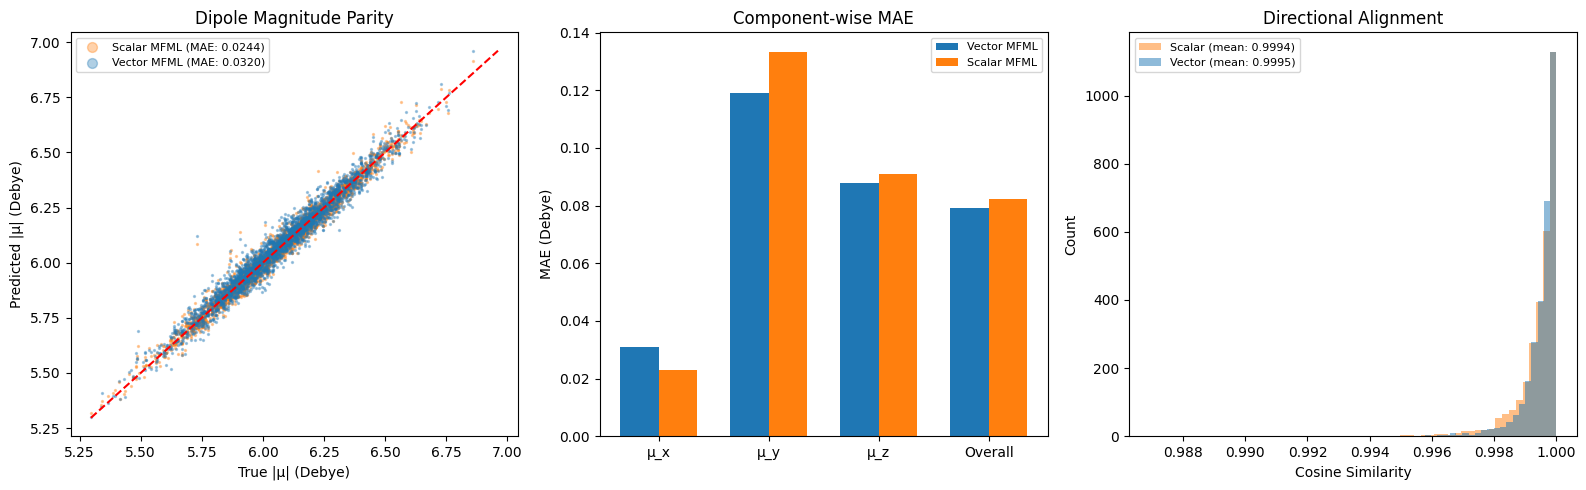

In [7]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

mag_true = np.linalg.norm(DPe_test_ref, axis=-1)
mag_vec = np.linalg.norm(DPe_pred, axis=-1)
mag_sca = np.linalg.norm(DPe_pred_scalar, axis=-1)

ax1.scatter(
    mag_true,
    mag_sca,
    s=2,
    alpha=0.35,
    color="#ff7f0e",
    label=f"Scalar MFML (MAE: {np.mean(np.abs(mag_sca - mag_true)):.4f})",
)
ax1.scatter(
    mag_true,
    mag_vec,
    s=2,
    alpha=0.35,
    color="#1f77b4",
    label=f"Vector MFML (MAE: {np.mean(np.abs(mag_vec - mag_true)):.4f})",
)
lims = [
    min(mag_true.min(), mag_sca.min(), mag_vec.min()),
    max(mag_true.max(), mag_sca.max(), mag_vec.max()),
]
ax1.plot(lims, lims, "r--", lw=1.5)
ax1.set_xlabel("True |μ| (Debye)")
ax1.set_ylabel("Predicted |μ| (Debye)")
ax1.set_title("Dipole Magnitude Parity")
ax1.legend(markerscale=5, fontsize=8)

comp_labels = ["μ_x", "μ_y", "μ_z", "Overall"]
vec_maes = list(comp_vec) + [mae_vec]
sca_maes = list(comp_sca) + [mae_sca]
x_pos = np.arange(len(comp_labels))
w = 0.35
ax2.bar(x_pos - w / 2, vec_maes, w, label="Vector MFML", color="#1f77b4")
ax2.bar(x_pos + w / 2, sca_maes, w, label="Scalar MFML", color="#ff7f0e")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(comp_labels)
ax2.set_ylabel("MAE (Debye)")
ax2.set_title("Component-wise MAE")
ax2.legend(fontsize=8)

ax3.hist(
    cos_sca,
    bins=60,
    color="#ff7f0e",
    edgecolor="none",
    alpha=0.5,
    label=f"Scalar (mean: {np.mean(cos_sca):.4f})",
)
ax3.hist(
    cos_vec,
    bins=60,
    color="#1f77b4",
    edgecolor="none",
    alpha=0.5,
    label=f"Vector (mean: {np.mean(cos_vec):.4f})",
)
ax3.set_xlabel("Cosine Similarity")
ax3.set_ylabel("Count")
ax3.set_title("Directional Alignment")
ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()